In [ ]:
# # This was for test
# import requests

# r = requests.get(
#     "https://archive-api.open-meteo.com/v1/archive",
#     params={
#         "latitude": 6.5244,
#         "longitude": 3.3792,
#         "start_date": "2024-01-01",
#         "end_date": "2024-01-07",
#         "hourly": "shortwave_radiation,temperature_2m",
#         "timezone": "Africa/Lagos",
#     },
#     timeout=60,
# )
# print(r.status_code)   # 200 means success
# print(r.json().keys())
# print(r.json()["hourly_units"])

In [ ]:
import numpy as np
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
CITIES = {
    "Lagos": (6.4561, 3.3958),
    "Abuja": (9.0722, 7.4913),
    "Kano": (12.0022, 8.5167),
    "Port Harcourt": (4.8241, 7.03361),
    "Maiduguri": (11.8333, 13.1500),
}

URL = "https://archive-api.open-meteo.com/v1/archive" # the v1/archive endpoint from OpenMeteo
VARS = [                        # the variables we'll need
    "shortwave_radiation",        # GHI, W/m².
    "direct_normal_irradiance",   # DNI
    "diffuse_radiation",          # DHI
    "temperature_2m",
    "cloud_cover",
    "wind_speed_10m",
]

def fetch_city(name, lat, lon, start, end):
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,  # "2022-01-01"
        "end_date": end,      # "2025-12-31"
        "hourly": ",".join(VARS),     #to join the list of varibles iwth comma because that's what the API needs
        "wind_speed_unit": "ms",
        "timezone": "Africa/Lagos",
    }
    r = requests.get(URL, params=params, timeout=60)  # requests adds the params to the URL as queries, like ...archive?latitude=6.52&longitude=3.37&
    r.raise_for_status()    # so we know if an error occurs

    df = pd.DataFrame(r.json()["hourly"]) # r.json() converts the response text into a Python dictionary
    df["time"] = pd.to_datetime(df["time"])
    df["city"] = name
    df["lat"], df["lon"] = lat, lon
    return df

frames = [fetch_city(n, la, lo, "2022-01-01", "2025-12-31")   # these are our strat and stop dates. 01-2022 to 12-2025 is over 30,000 hours. 2024 was a leap year
          for n, (la, lo) in CITIES.items()]
data = pd.concat(frames, ignore_index=True)
data.to_csv("nigeria_weather.csv")  # or .to_csv

print(data.groupby("city").size())  # let's confirm that the hours are correct

city
Abuja            35064
Kano             35064
Lagos            35064
Maiduguri        35064
Port Harcourt    35064
dtype: int64


# Choosing the variables
The goaol is panel output so these are most possible factors that may affect it:  
1. How much sunlight arrives. This is the biggest factor. Sunlight comes in three flavours:  
- shortwave_radiation is GHI (global horizontal irradiance), the total sunlight on a flat horizontal surface.
- direct_normal_irradiance is DNI, the sunlight coming straight from the sun’s disc.
- diffuse_radiation is DHI, the sunlight scattered by the sky and clouds.
pvlib wants these three to work out how much light hits a tilted panel.  

2. Temperature. Panels get less efficient as they heat up. temperature_2m feeds that correction.  

3. Wind. Wind cools the panel, so it affects the temperature correction too.

4. Cloud cover. To be honest, it’s the least essential. Cloud effects are already baked into the radiation numbers. I included it as a likely useful feature for the forecasting model later, but you could drop it from the first version.

## **How to choose in general:**

Work backwards from the physics or model. Read what your downstream tool needs.
1. pvlib’s docs list its inputs, so start there.
Read the variable table in the docs. It lists everything, with units and whether each is instantaneous or averaged.  
Start small, then add. Begin with the necessary few and add variables later when you have evidence they help.  

2. Humidity, pressure and precipitation are candidates. Your ML model’s feature importances can tell you.

3. Check for shortcuts. The docs list global_tilted_irradiance, where Open-Meteo itself calculates sunlight on a tilted panel. It’s worth knowing about, though doing it with pvlib teaches you more.

In [ ]:
# Now, we see what our dataset looks like
data.tail(3)

,time,shortwave_radiation,direct_normal_irradiance,diffuse_radiation,temperature_2m,cloud_cover,wind_speed_10m,city,lat,lon
175317,2025-12-31 21:00:00,0.0,0.0,0.0,27.1,0,2.45,Maiduguri,11.8333,13.15
175318,2025-12-31 22:00:00,0.0,0.0,0.0,25.7,0,2.95,Maiduguri,11.8333,13.15
175319,2025-12-31 23:00:00,0.0,0.0,0.0,24.8,0,3.65,Maiduguri,11.8333,13.15


In [ ]:
# I wanted to plot day vs night but it seems kinda pointless

# lagos = data[data["city"]=="Lagos"]["time"]
# # plt.plot(lagos[8:] >)
# day = (lagos.dt.hour >= 7) & (lagos.dt.hour < 19)
# night = (lagos.dt.hour >= 19) & (lagos.dt.hour < 4)

# plt.plot(day, night)


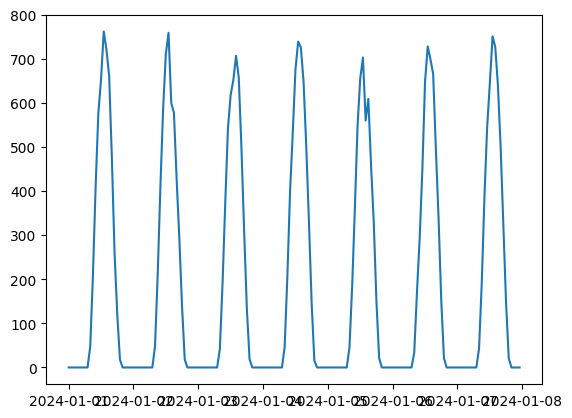

In [ ]:
# Plot a graph of short wave radiation against a week in Lagos
lagos = data[data["city"]=="Lagos"]
week = lagos[(lagos["time"] >= "2024-01-01") & (lagos["time"] < "2024-01-08")]
plt.plot(week["time"], week["shortwave_radiation"])
plt.show()


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175320 entries, 0 to 175319
Data columns (total 10 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   time                      175320 non-null  datetime64[ns]
 1   shortwave_radiation       175320 non-null  float64       
 2   direct_normal_irradiance  175320 non-null  float64       
 3   diffuse_radiation         175320 non-null  float64       
 4   temperature_2m            175320 non-null  float64       
 5   cloud_cover               175320 non-null  int64         
 6   wind_speed_10m            175320 non-null  float64       
 7   city                      175320 non-null  object        
 8   lat                       175320 non-null  float64       
 9   lon                       175320 non-null  float64       
dtypes: datetime64[ns](1), float64(7), int64(1), object(1)
memory usage: 13.4+ MB


In [ ]:
data[["shortwave_radiation", "direct_normal_irradiance", "diffuse_radiation", "temperature_2m", "cloud_cover"]].describe()

,shortwave_radiation,direct_normal_irradiance,diffuse_radiation,temperature_2m,cloud_cover
count,175320.000000,175320.000000,175320.000000,175320.000000,175320.000000
mean,220.035860,189.932527,85.432444,26.754892,67.378508
std,297.041961,262.558114,106.613586,4.294941,39.235459
min,0.000000,0.000000,0.000000,10.400000,0.000000
25%,0.000000,0.000000,0.000000,24.100000,28.000000
50%,11.000000,0.000000,10.000000,26.400000,93.000000
75%,425.000000,387.800000,170.000000,29.100000,100.000000
max,1014.000000,869.700000,472.000000,44.300000,100.000000


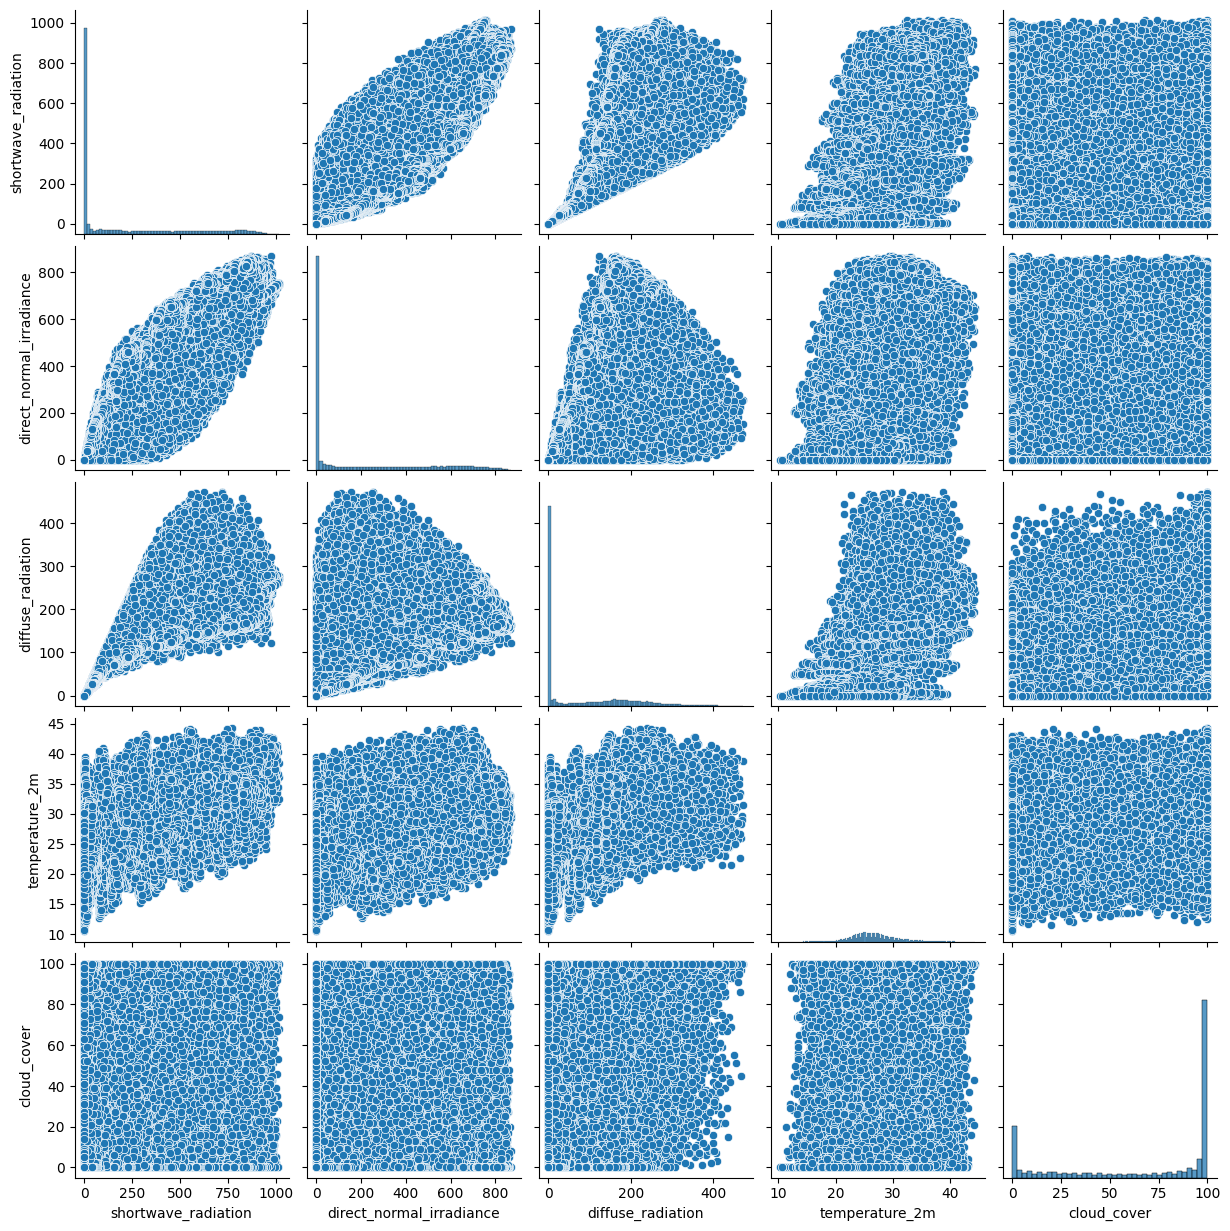

In [ ]:
sns.pairplot(data[["shortwave_radiation", "direct_normal_irradiance", "diffuse_radiation", "temperature_2m", "cloud_cover"]])
plt.show()

In [ ]:
data["hour"] = data["time"].dt.hour
data["month"] = data["time"].dt.month

In [ ]:
# Typical day shape, per city
profile = data.groupby(["city", "hour"])["shortwave_radiation"].mean().unstack(0)   # add unstack to move the cities to the top
profile

city,Abuja,Kano,Lagos,Maiduguri,Port Harcourt
hour,,,,,
0,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.000000,0.000000
5,0.000000,0.000000,0.000000,0.000000,0.000000
6,0.000000,0.000000,0.000000,0.274470,0.000000
7,12.862423,18.308008,3.077344,43.360712,10.225188
8,123.553730,145.215606,76.581109,203.890486,110.024641


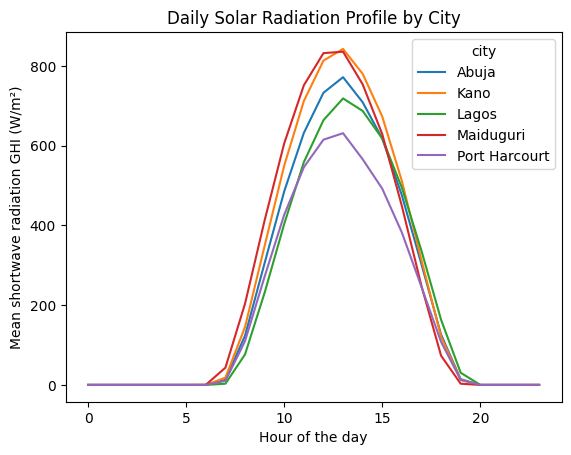

In [ ]:
# plot the daily Solar Radiation Profile for each city
profile.plot() # the index hour is automatically put on the x-axis

plt.xlabel("Hour of the day")
plt.ylabel("Mean shortwave radiation GHI (W/m²)")
plt.title("Daily Solar Radiation Profile by City")

plt.show()

0 irradiance between 20:00 and around 7:00 which is valid as it's mostly nighttime

In [ ]:
# the seasonality per city for each month
monthly =data.groupby(["city", "month"])["shortwave_radiation"].mean().unstack(0)
monthly

city,Abuja,Kano,Lagos,Maiduguri,Port Harcourt
month,,,,,
1,241.002016,242.302083,209.053427,244.997984,207.793683
2,254.714602,260.488569,222.094027,262.627581,219.116519
3,244.599126,272.927419,218.458669,274.656922,190.339382
4,232.982292,265.298611,215.818056,269.762153,193.840625
5,229.167339,258.743616,219.135753,262.381720,186.941532
6,199.201389,237.498958,185.799653,237.040278,161.760069
7,181.610551,222.757056,191.511089,212.852823,154.898858
8,172.045363,196.477151,201.293347,195.752352,172.308132
9,194.163194,235.232986,200.816667,228.439583,159.807639


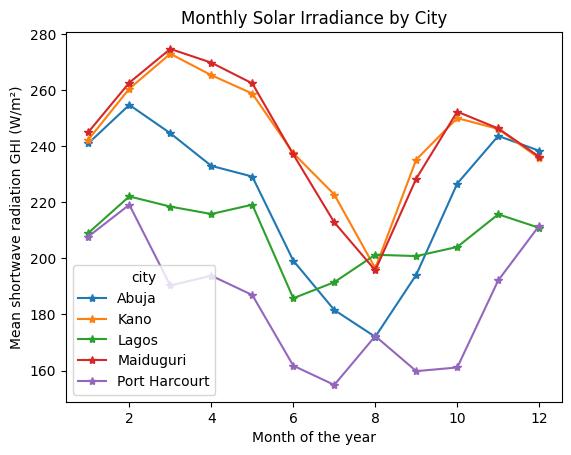

In [ ]:
monthly.plot(marker = '*')

plt.xlabel("Month of the year")
plt.ylabel("Mean shortwave radiation GHI (W/m²)")
plt.title("Monthly Solar Irradiance by City")

plt.show()

most of the city's irradiance dip between July and September, which is typical rainy season.  
Kano and Maiduguri have high irradiance from around February to April which is typical for the north in dry season

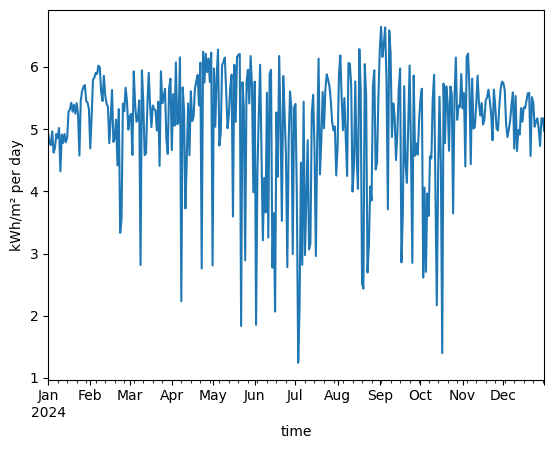

In [ ]:
# filter for Lagos
lagos = data[data["city"] == "Lagos"]

# Set the time column as index
lagos = lagos.set_index("time")

# Sum up the hours, then divide by 1000 to convert W/m2 to kWh/m2
daily_eng = lagos["shortwave_radiation"].resample("D").sum()
daily_eng = daily_eng/1000

# plot the graph for just 2024
daily_eng["2024"].plot()
plt.ylabel("kWh/m² per day")
plt.show()

In [ ]:
! pip install pvlib
import pvlib
from pvlib.location import Location
from pvlib.pvsystem import PVSystem
from pvlib.modelchain import ModelChain

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 31.6 MB/s  0:00:00


In [ ]:
#### We've done extra analysis.
#### Now we start with pvlib analysis for Lagos


city, lat, lon = "Lagos", 6.4561, 3.3958
df = data[data["city"] == city].copy()

# We Fix the timestamps
# A row stamped 13:00 holds the average sunlight from 12:00 to 13:00.
# But pvlib works on  where the sun is at the stamped moment,
# the sun at 13:00 isn’t where it was on average during that hour.
# Moving it to the middle of the hour (- 30 minutes) moves the stamp to 12:30.
df["time"] = df["time"] - pd.Timedelta(minutes=30)
df = df.set_index("time").tz_localize("Africa/Lagos") # use tz_localize because pvlib needs to know which timezone it’s working with


In [ ]:
# pvlib expects these field names for the weather table: ghi, dni, dhi, temp_air, wind_speed
weather = pd.DataFrame({
    "ghi": df["shortwave_radiation"],
    "dni": df["direct_normal_irradiance"],
    "dhi": df["diffuse_radiation"],
    "temp_air": df["temperature_2m"],
    "wind_speed": df["wind_speed_10m"] / 3.6,   # to convert km/h to m/s: x 10/36 or /3.6
})

In [ ]:
#  Describe the panel system: 5 kW, tilted 10°, facing south
location = Location(lat, lon, tz="Africa/Lagos")
temp_params = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]

system = PVSystem(
    surface_tilt=10,            # the panels lean 10° up from flat
    surface_azimuth=180,                      # 180: facing due south
    module_parameters={"pdc0": 5000, "gamma_pdc": -0.004},
    inverter_parameters={"pdc0": 5000},
    temperature_model_parameters=temp_params,
)


# Now, run the modelchain
mc = ModelChain.with_pvwatts(system, location)
mc.run_model(weather)
pv_kw = mc.results.ac / 1000      # older pvlib versions: mc.ac

- `open_rack_glass_glass` means panels are on an open frame with glass on both sides. **We're assuming this**  

- surface azimuth is solar panel direction. And with Nigeria being just above the equator, solar panels mostly face due south (180 degrees azimuth).
- "pdc0": 5000 is the panel's rated power in watts (under test conditions), since we're assuming it'a 5kW panel
- gamma_pdc: -0.004 is the heat loss, the fraction of power lost per °C. Negative because power goes down as it gets hotter
- `pdc0` is the inverter size. It converts the panel's DC to AC
- `temp_params` is how hot the panels get from sun and wind.  



ModelChain is an assembly line: weather → sun position → light on the tilted panel → panel temperature → DC power → AC power. with_pvwatts picks the simple PVWatts version of each stage, and run_model pushes your weather through it. mc.results.ac is the AC power in watts, and dividing by 1000 gives kW.


count    35064.000000
mean         0.779170
std          1.045968
min          0.000000
25%          0.000000
50%          0.000000
75%          1.573614
max          3.438603
Name: p_mp, dtype: float64
Capacity factor: 0.15583402887881284


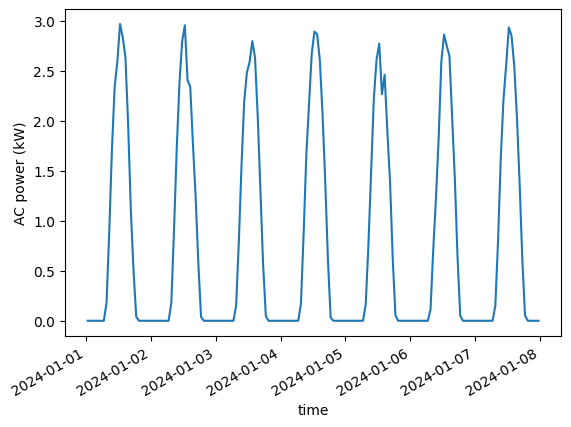

In [ ]:
print(pv_kw.describe())
print("Capacity factor:", pv_kw.mean() / 5)

pv_kw["2024-01-01":"2024-01-07"].plot()
plt.ylabel("AC power (kW)"); plt.show()

Capacity factor is 0.1558. It should ideally stay the same for panels in the same area even when one has higher rating.  
So I tested m=by changing the ratings inn the module and inverter parameters (pdc0) to 10000 from the 5000 we assumed. We're assuming the panel and inverter size are same, we are not factoring in clipping, where inverter size is less than pnael size.  
Then since:  
caapcity factor = average power/ rated power,  
I changed the rated power to 10 for the quick experiment.  

And the capacity factor remained the same around 0.1558.  
Capacity factor measures how well the location and weather suit solar. so we'll use it as the target for the forecasting model later.

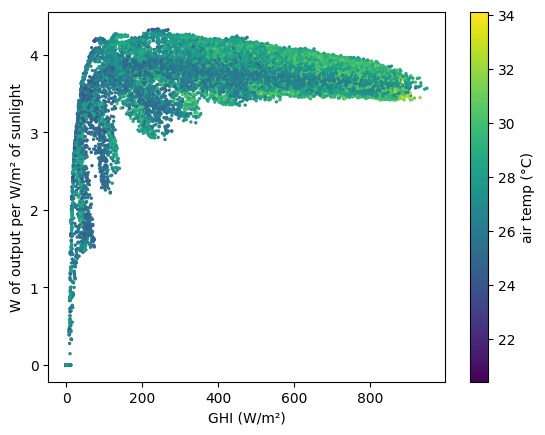

In [ ]:
plt.scatter(weather["ghi"], pv_kw * 1000 / weather["ghi"].clip(lower=1),
            c=weather["temp_air"], s=2)
plt.colorbar(label="air temp (°C)")
plt.xlabel("GHI (W/m²)"); plt.ylabel("W of output per W/m² of sunlight")
plt.show()

In [ ]:
## SInce we've done for Lagos, let's run for the other states too


def simulate_pv(city_df, lat, lon, kw=5, tilt=10):
  # Fix the timestamps
  df["time"] = df["time"] - pd.Timedelta(minutes=30)
  df = df.set_index("time").tz_localize("Africa/Lagos")

  # Build the weather table pvlib expects
  weather = pd.DataFrame({
      "ghi": df["shortwave_radiation"],
      "dni": df["direct_normal_irradiance"],
      "dhi": df["diffuse_radiation"],
      "temp_air": df["temperature_2m"],
      "wind_speed": df["wind_speed_10m"] / 3.6,
  })

  # Describe the panel system: 5 kW, tilted 10°, facing south
  location = Location(lat, lon, tz="Africa/Lagos")
  temp_params = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]
  system = PVSystem(
      surface_tilt=10,
      surface_azimuth=180,                      # 180 = facing south
      module_parameters={"pdc0": 5000, "gamma_pdc": -0.004},   # watts
      inverter_parameters={"pdc0": 5000},
      temperature_model_parameters=temp_params,
  )

  #
  mc = ModelChain.with_pvwatts(system, location)
  mc.run_model(weather)
  pv_kw = mc.results.ac / 1000

  return pv_kw

results ={}
for name, (lon, lat) in CITIES.items():
  city_df = data[data["city"] == name].copy()
  results[name] = simulate_pv(city_df, lat, lon)


949.0


In [ ]:
print(pv_kw.mean() / 10)

0.07791701443940642
